# Task 4 — Emissions Modelling Revised

## Aim of this notebook

This notebook revises the emissions modelling task by improving the initial emissions model used in the previous version.

In the first version, CO₂ savings were estimated using a simple model based on:

$$
\text{CO₂ saved} = \text{traffic flow} \times \text{segment length} \times \text{constant emission factor}
$$

This approach was useful as a baseline, but it made the emissions map look very similar to the traffic flow map because the emission factor was mostly constant across all road segments.

In this revised version, the model is improved by adding road-segment characteristics from OpenStreetMap, such as:

- road type,
- speed-related assumptions,
- and segment length effects.

The goal is to create a more realistic emissions model where emissions vary not only by traffic volume, but also by the characteristics of the road segment.

## Expected outputs

This revised notebook will produce:

1. an improved emissions dataset at road-segment level,
2. visualizations of emissions savings,
3. comparison between the simple and improved emissions models,
4. statistics and interpretation,
5. assumptions, limitations, and policy insights.

## Step 1 — Load Required Libraries and Traffic Flow Dataset

The revised emissions model builds directly on the traffic flow dataset created in Task 3.

The Task 3 dataset contains road-segment-level bicycle traffic flows, where each row represents an OpenStreetMap edge used by the routed bicycle trips.

The key columns are:

- `u` and `v`: network node identifiers defining each road segment,
- `total_flow`: number of routed bicycle trips using the segment,
- `length_m`: segment length in meters,
- `geometry`: road segment geometry.

This dataset forms the baseline input for emissions modelling.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
import osmnx as ox
import networkx as nx

# Load Task 3 traffic flow dataset
flow_gdf = gpd.read_file("flow_data.gpkg")

# Convert length to kilometers
flow_gdf["length_km"] = flow_gdf["length_m"] / 1000

print("Flow dataset loaded successfully")
print("Number of road segments:", len(flow_gdf))
print("\nColumns:")
print(flow_gdf.columns)

print("\nFlow statistics:")
print(flow_gdf["total_flow"].describe())

print("\nLength statistics:")
print(flow_gdf["length_m"].describe())

print("\nMissing values:")
print(flow_gdf.isnull().sum())

flow_gdf.head()

Flow dataset loaded successfully
Number of road segments: 5631

Columns:
Index(['u', 'v', 'total_flow', 'length_m', 'geometry', 'length_km'], dtype='str')

Flow statistics:
count    5631.000000
mean       41.888830
std        70.981193
min         1.000000
25%         2.000000
50%         8.000000
75%        51.000000
max       606.000000
Name: total_flow, dtype: float64

Length statistics:
count    5631.000000
mean       69.985055
std        58.829243
min         0.847314
25%        26.192951
50%        58.338924
75%        88.458480
max       652.526926
Name: length_m, dtype: float64

Missing values:
u             0
v             0
total_flow    0
length_m      0
geometry      0
length_km     0
dtype: int64


,u,v,total_flow,length_m,geometry,length_km
0,5451987123,297110085,238,46.263959,"LINESTRING (-74.03022 40.73586, -74.03032 40.7...",0.046264
1,297110085,297110097,206,46.277329,"LINESTRING (-74.03037 40.73546, -74.03038 40.7...",0.046277
2,297110097,7217917595,206,20.824373,"LINESTRING (-74.0309 40.73551, -74.03115 40.73...",0.020824
3,7217917595,103866250,207,26.904055,"LINESTRING (-74.03115 40.73555, -74.03128 40.7...",0.026904
4,103866250,4988900669,78,34.830991,"LINESTRING (-74.03146 40.73561, -74.03143 40.7...",0.034831


### Interpretation

The Task 3 traffic flow dataset was loaded and contains 5,631 road segments. Each segment represents an OpenStreetMap edge used by at least one routed bicycle trip.

The key columns required for emissions modelling are present:

- `u` and `v`: the start and end nodes of each road segment,
- `total_flow`: the number of routed bicycle trips using that segment,
- `length_m`: the segment length in meters,
- `geometry`: the spatial line geometry of the road segment,
- `length_km`: the segment length converted into kilometers.

The flow distribution is highly skewed. The mean flow is approximately 41.9 trips per segment, while the median is only 8 trips per segment. This indicates that most road segments have relatively low usage, while a smaller number of corridors carry much higher bicycle flows. The maximum observed flow is 606 trips on one segment.

The segment lengths are typical for an urban street network, with an average length of about 70 meters. No missing values are present in the required columns, which means the dataset is complete and suitable for emissions modelling.

This dataset provides the baseline traffic-flow input for the revised emissions model.

## Step 2 — Rebuild the OSM Bicycle Network and Check Edge Matching

To improve the emissions model, road attributes such as road type, speed limit, and lane count need to be extracted from the OpenStreetMap network.

The traffic flow dataset contains only the edge identifiers (`u`, `v`) and flow values. Therefore, the original bicycle network graph must be rebuilt so that each flow edge can be matched back to its corresponding OpenStreetMap edge attributes.

Before extracting attributes, it is important to check whether the `u`, `v` node pairs in the flow dataset still exist in the rebuilt graph.

In [2]:
# Rebuild the same bicycle network used in Task 3

places = [
    "Jersey City, New Jersey, USA",
    "Hoboken, New Jersey, USA"
]

G = ox.graph_from_place(places, network_type="bike")

# Keep only the largest connected component, same as Task 3
largest_cc = max(nx.connected_components(G.to_undirected()), key=len)
G = G.subgraph(largest_cc).copy()

print("Graph rebuilt successfully")
print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))

Graph rebuilt successfully
Nodes: 6164
Edges: 14676


In [3]:
# Check how many flow_gdf edges exist in the rebuilt graph

def edge_exists(row):
    u = row["u"]
    v = row["v"]
    return G.has_edge(u, v)

flow_gdf["edge_exists_in_G"] = flow_gdf.apply(edge_exists, axis=1)

matched_edges = flow_gdf["edge_exists_in_G"].sum()
total_edges = len(flow_gdf)
match_rate = matched_edges / total_edges * 100

print("Matched edges:", matched_edges)
print("Total flow edges:", total_edges)
print(f"Match rate: {match_rate:.2f}%")

flow_gdf["edge_exists_in_G"].value_counts()

Matched edges: 5631
Total flow edges: 5631
Match rate: 100.00%


edge_exists_in_G
True    5631
Name: count, dtype: int64

### Interpretation

The OpenStreetMap bicycle network was rebuilt successfully for Jersey City and Hoboken, matching the network used in Task 3.

The rebuilt graph contains:

- 6,164 nodes
- 14,676 edges

The edge matching check confirms that all 5,631 flow edges from the Task 3 traffic flow dataset exist in the rebuilt graph. The match rate is therefore 100%.

This is an important validation step because it confirms that the `u` and `v` node identifiers in the flow dataset are compatible with the rebuilt OSM graph. Therefore, road attributes such as road type, speed limit, and lane information can now be extracted reliably from the graph and attached to the emissions dataset.

This means the revised emissions model can now move beyond a constant emission factor and include road-segment characteristics.

## Step 3 — Adding Road Attributes for an Improved Emissions Model

The initial emissions model estimated CO₂ savings using traffic flow, segment length, and a weighted average emission factor. While this provides a clear and interpretable baseline, it assumes that all road segments have the same characteristics like traffic Flow.

So to improve the realism of the model, additional OpenStreetMap road attributes are added to each edge:

- `highway`: road classification, such as residential, primary, secondary, cycleway, or service road
- `maxspeed`: posted speed limit where available
- `lanes`: number of traffic lanes where available

These attributes allow the emissions model to vary by road type and road conditions instead of relying only on a constant emission factor. 

In [4]:
# Add OSM road attributes to each edge in flow_gdf

def get_edge_attribute(u, v, attribute):
    """
    Extract an attribute from the OSMnx graph edge.
    Returns None if the attribute is missing.
    """
    try:
        edge_data = G.get_edge_data(u, v)[0]
        return edge_data.get(attribute, None)
    except:
        return None


flow_gdf["highway"] = flow_gdf.apply(
    lambda row: get_edge_attribute(row["u"], row["v"], "highway"),
    axis=1
)

flow_gdf["maxspeed"] = flow_gdf.apply(
    lambda row: get_edge_attribute(row["u"], row["v"], "maxspeed"),
    axis=1
)

flow_gdf["lanes"] = flow_gdf.apply(
    lambda row: get_edge_attribute(row["u"], row["v"], "lanes"),
    axis=1
)

# Check results
flow_gdf[["u", "v", "total_flow", "length_m", "highway", "maxspeed", "lanes"]].head()

,u,v,total_flow,length_m,highway,maxspeed,lanes
0,5451987123,297110085,238,46.263959,tertiary,20 mph,None
1,297110085,297110097,206,46.277329,tertiary,20 mph,2
2,297110097,7217917595,206,20.824373,tertiary,20 mph,2
3,7217917595,103866250,207,26.904055,tertiary,20 mph,3
4,103866250,4988900669,78,34.830991,secondary,20 mph,3


In [5]:
print("Highway types:")
print(flow_gdf["highway"].value_counts(dropna=False).head(20))

print("\nMaxspeed values:")
print(flow_gdf["maxspeed"].value_counts(dropna=False).head(20))

print("\nLane values:")
print(flow_gdf["lanes"].value_counts(dropna=False).head(20))

Highway types:
highway
residential                    1809
tertiary                       1205
service                        1129
secondary                       926
primary                         226
pedestrian                       91
unclassified                     90
cycleway                         46
trunk                            30
path                             26
[residential, service]           21
tertiary_link                    10
trunk_link                        6
primary_link                      4
[residential, pedestrian]         2
[residential, secondary]          2
[unclassified, pedestrian]        2
[unclassified, residential]       2
secondary_link                    2
[primary, tertiary]               1
Name: count, dtype: int64

Maxspeed values:
maxspeed
None                4415
20 mph               783
25 mph               361
10 mph                24
35 mph                19
15 mph                15
5 mph                 11
[25 mph, 35 mph]       1
[20 

### Interpretation

Road attributes were successfully extracted from the OpenStreetMap bicycle network and attached to the traffic flow dataset.

The `highway` attribute is available for all road segments and shows that the used cycling routes pass through a mix of road types. The most common road classes are:

- residential roads,
- tertiary roads,
- service roads,
- secondary roads,
- and primary roads.

This is useful because emissions can now be varied by road type instead of using one constant emission factor for the entire network.

The `maxspeed` attribute is only available for part of the network. Most segments have missing speed information, while available values include 20 mph, 25 mph, 10 mph, 35 mph, and smaller local speed limits. This is expected because OpenStreetMap data is often incomplete for speed-related attributes.

The `lanes` attribute is also missing for many segments, but where available, most roads have 1 to 3 lanes. Some values appear as lists, such as `[3, 2]`, meaning that multiple lane values may be stored for the same OSM edge.

Overall, this step successfully adds an additional layer of road-segment information to the emissions dataset. Since `highway` has the best coverage, it will be used as the main attribute for improving the emissions model. Speed and lane information can be used carefully as secondary adjustment factors, but their missing values must be handled before modelling.

## Step 4 — Clean Road Attribute Values

The extracted OpenStreetMap attributes contain mixed data formats. Some values are simple strings, while others are stored as lists. In addition, many `maxspeed` and `lanes` values are missing.

Before these attributes can be used in the emissions model, they need to be cleaned into consistent formats.

The cleaning strategy is:

- simplify `highway` values by taking the first road type if multiple are listed,
- convert `maxspeed` values from strings such as `"20 mph"` into numeric speed values,
- convert `lanes` values into numeric values,
- fill missing speed and lane values using reasonable assumptions based on road type.

This step prepares the dataset for an improved road-attribute-based emissions model.

In [6]:
import re

def clean_highway(value):
    """
    Clean highway values.
    If the value is a list, take the first road type.
    """
    if isinstance(value, list):
        return value[0]
    return value


def clean_maxspeed(value):
    """
    Convert maxspeed values like '20 mph' or ['25 mph', '35 mph'] to numeric mph.
    If multiple speeds exist, take the first one.
    """
    if isinstance(value, list):
        value = value[0]
    
    if pd.isna(value):
        return np.nan
    
    value = str(value)
    numbers = re.findall(r"\d+", value)
    
    if len(numbers) > 0:
        return float(numbers[0])
    else:
        return np.nan


def clean_lanes(value):
    """
    Convert lanes values to numeric.
    If multiple lane values exist, take the first one.
    """
    if isinstance(value, list):
        value = value[0]
    
    if pd.isna(value):
        return np.nan
    
    try:
        return float(value)
    except:
        return np.nan


flow_gdf["highway_clean"] = flow_gdf["highway"].apply(clean_highway)
flow_gdf["maxspeed_mph"] = flow_gdf["maxspeed"].apply(clean_maxspeed)
flow_gdf["lanes_clean"] = flow_gdf["lanes"].apply(clean_lanes)

flow_gdf[[
    "highway", "highway_clean",
    "maxspeed", "maxspeed_mph",
    "lanes", "lanes_clean"
]].head(10)

,highway,highway_clean,maxspeed,maxspeed_mph,lanes,lanes_clean
0,tertiary,tertiary,20 mph,20.0,None,NaN
1,tertiary,tertiary,20 mph,20.0,2,2.0
2,tertiary,tertiary,20 mph,20.0,2,2.0
3,tertiary,tertiary,20 mph,20.0,3,3.0
4,secondary,secondary,20 mph,20.0,3,3.0
5,secondary,secondary,20 mph,20.0,2,2.0
6,secondary,secondary,20 mph,20.0,2,2.0
7,secondary,secondary,20 mph,20.0,2,2.0
8,secondary,secondary,20 mph,20.0,2,2.0
9,secondary,secondary,20 mph,20.0,2,2.0


In [7]:
print("Cleaned highway values:")
print(flow_gdf["highway_clean"].value_counts(dropna=False).head(20))

print("\nCleaned speed values:")
print(flow_gdf["maxspeed_mph"].value_counts(dropna=False).head(20))

print("\nCleaned lane values:")
print(flow_gdf["lanes_clean"].value_counts(dropna=False).head(20))

Cleaned highway values:
highway_clean
residential       1834
tertiary          1205
service           1129
secondary          926
primary            227
unclassified        94
pedestrian          91
cycleway            46
trunk               30
path                26
tertiary_link       11
trunk_link           6
primary_link         4
secondary_link       2
Name: count, dtype: int64

Cleaned speed values:
maxspeed_mph
NaN     4415
20.0     785
25.0     362
10.0      24
35.0      19
15.0      15
5.0       11
Name: count, dtype: int64

Cleaned lane values:
lanes_clean
NaN    4271
2.0     669
1.0     295
3.0     234
4.0      69
5.0      55
6.0      38
Name: count, dtype: int64


### Interpretation

The road attribute cleaning step was successful. The `highway` attribute was converted into a consistent `highway_clean` column, and this attribute has complete coverage across the traffic flow dataset.

The cleaned road type distribution shows that most bicycle traffic occurs on residential, tertiary, service, and secondary roads. This is consistent with an urban cycling network, where trips are distributed across local streets and connector roads rather than only major arterials.

The `maxspeed` attribute was converted into numeric speed values in miles per hour. However, speed information is missing for a large number of segments. This is expected because OpenStreetMap attributes are not always complete. Therefore, missing speed values should be filled using reasonable assumptions based on road type.

The `lanes` attribute was also converted into numeric form, but it has many missing values as well. Because of this, lane information should be treated as a secondary adjustment rather than the main driver of the emissions model.

Overall, the cleaned attributes are suitable for improving the emissions model. The `highway_clean` column will be used as the main source of road-type variation, while speed and lane values will be filled and used cautiously as supporting factors.

## Step 5 — Data-Informed Imputation of Missing Speed and Lane Values

The OpenStreetMap road attributes contain missing values for `maxspeed_mph` and `lanes_clean`. Instead of filling these values using only manual assumptions, a data-informed imputation approach is used.

The key idea is to separate three cases:

1. Observed from OSM  
   The value was directly available in the OpenStreetMap data.

2. Imputed from similar edges  
   The value was missing, but it could be estimated using observed values from similar road segments in the dataset.

3. Assumed from road type  
   No suitable observed value was available, so a fallback road-type-based assumption was used.

This separation is important because it makes the modelling process transparent. It allows us to report how much of the final dataset is based on observed data, how much is data-informed imputation, and how much depends on assumptions.

For speed values, missing values are filled using the following hierarchy:

1. observed OSM speed, if available;
2. median speed for the same road type and lane count;
3. median speed for the same road type;
4. fallback road-type assumption.

For lane values, missing values are filled using:

1. observed OSM lane count, if available;
2. median lane count for the same road type and speed value;
3. median lane count for the same road type;
4. fallback road-type assumption.

The original OSM columns are preserved, and the completed values are stored separately as:

- `final_speed_mph`
- `final_lanes`

The source of each value is stored in:

- `speed_source`
- `lane_source`

In [8]:
# ----------------------------------------------------
# Step 5A — Create observed-data lookup tables
# ----------------------------------------------------

# Speed lookup: median speed by road type + lane count
speed_by_highway_lanes = (
    flow_gdf
    .dropna(subset=["maxspeed_mph", "lanes_clean"])
    .groupby(["highway_clean", "lanes_clean"])["maxspeed_mph"]
    .median()
    .to_dict()
)

# Speed lookup: median speed by road type
speed_by_highway = (
    flow_gdf
    .dropna(subset=["maxspeed_mph"])
    .groupby("highway_clean")["maxspeed_mph"]
    .median()
    .to_dict()
)

# Lane lookup: median lane count by road type + speed
lanes_by_highway_speed = (
    flow_gdf
    .dropna(subset=["lanes_clean", "maxspeed_mph"])
    .groupby(["highway_clean", "maxspeed_mph"])["lanes_clean"]
    .median()
    .to_dict()
)

# Lane lookup: median lane count by road type
lanes_by_highway = (
    flow_gdf
    .dropna(subset=["lanes_clean"])
    .groupby("highway_clean")["lanes_clean"]
    .median()
    .to_dict()
)

In [9]:
# ----------------------------------------------------
# Step 5B — Define fallback assumptions
# These are only used when no observed pattern exists
# ----------------------------------------------------

fallback_speed_by_highway = {
    "trunk": 35,
    "trunk_link": 30,
    "primary": 30,
    "primary_link": 25,
    "secondary": 25,
    "secondary_link": 20,
    "tertiary": 20,
    "tertiary_link": 20,
    "residential": 20,
    "service": 15,
    "unclassified": 20,
    "pedestrian": 10,
    "cycleway": 10,
    "path": 10
}

fallback_lanes_by_highway = {
    "trunk": 4,
    "trunk_link": 2,
    "primary": 3,
    "primary_link": 2,
    "secondary": 2,
    "secondary_link": 2,
    "tertiary": 2,
    "tertiary_link": 1,
    "residential": 1,
    "service": 1,
    "unclassified": 1,
    "pedestrian": 1,
    "cycleway": 1,
    "path": 1
}

In [10]:
# ----------------------------------------------------
# Step 5C — Impute speed and track source
# ----------------------------------------------------

def fill_speed_with_source(row):
    """
    Returns both final speed value and source category.
    """
    
    # 1. Keep observed OSM value
    if not pd.isna(row["maxspeed_mph"]):
        return row["maxspeed_mph"], "observed_from_OSM"
    
    highway = row["highway_clean"]
    lanes = row["lanes_clean"]
    
    # 2. Impute from same highway + lanes
    if not pd.isna(lanes):
        key = (highway, lanes)
        if key in speed_by_highway_lanes:
            return speed_by_highway_lanes[key], "imputed_from_highway_and_lanes"
    
    # 3. Impute from same highway
    if highway in speed_by_highway:
        return speed_by_highway[highway], "imputed_from_highway"
    
    # 4. Fallback assumption
    return fallback_speed_by_highway.get(highway, 20), "assumed_from_road_type"


speed_results = flow_gdf.apply(fill_speed_with_source, axis=1)

flow_gdf["final_speed_mph"] = speed_results.apply(lambda x: x[0])
flow_gdf["speed_source"] = speed_results.apply(lambda x: x[1])

In [11]:
# ----------------------------------------------------
# Step 5D — Impute lanes and track source
# ----------------------------------------------------

def fill_lanes_with_source(row):
    """
    Returns both final lane value and source category.
    """
    
    # 1. Keep observed OSM value
    if not pd.isna(row["lanes_clean"]):
        return row["lanes_clean"], "observed_from_OSM"
    
    highway = row["highway_clean"]
    speed = row["maxspeed_mph"]
    
    # 2. Impute from same highway + speed
    if not pd.isna(speed):
        key = (highway, speed)
        if key in lanes_by_highway_speed:
            return lanes_by_highway_speed[key], "imputed_from_highway_and_speed"
    
    # 3. Impute from same highway
    if highway in lanes_by_highway:
        return lanes_by_highway[highway], "imputed_from_highway"
    
    # 4. Fallback assumption
    return fallback_lanes_by_highway.get(highway, 1), "assumed_from_road_type"


lane_results = flow_gdf.apply(fill_lanes_with_source, axis=1)

flow_gdf["final_lanes"] = lane_results.apply(lambda x: x[0])
flow_gdf["lane_source"] = lane_results.apply(lambda x: x[1])

In [12]:
# ----------------------------------------------------
# Step 5E — Report source statistics
# ----------------------------------------------------

total_segments = len(flow_gdf)

speed_source_counts = flow_gdf["speed_source"].value_counts()
speed_source_percent = (speed_source_counts / total_segments * 100).round(2)

lane_source_counts = flow_gdf["lane_source"].value_counts()
lane_source_percent = (lane_source_counts / total_segments * 100).round(2)

speed_source_summary = pd.DataFrame({
    "count": speed_source_counts,
    "percentage": speed_source_percent
})

lane_source_summary = pd.DataFrame({
    "count": lane_source_counts,
    "percentage": lane_source_percent
})

print("Speed value source summary:")
display(speed_source_summary)

print("\nLane value source summary:")
display(lane_source_summary)

print("\nFinal speed summary:")
print(flow_gdf["final_speed_mph"].describe())

print("\nFinal lane summary:")
print(flow_gdf["final_lanes"].describe())

Speed value source summary:


,count,percentage
speed_source,,
imputed_from_highway,3598,63.90
observed_from_OSM,1216,21.59
imputed_from_highway_and_lanes,722,12.82
assumed_from_road_type,95,1.69



Lane value source summary:


,count,percentage
lane_source,,
imputed_from_highway,3558,63.19
observed_from_OSM,1360,24.15
imputed_from_highway_and_speed,596,10.58
assumed_from_road_type,117,2.08



Final speed summary:
count    5631.000000
mean       18.843900
std         6.021333
min         5.000000
25%        20.000000
50%        20.000000
75%        20.000000
max        35.000000
Name: final_speed_mph, dtype: float64

Final lane summary:
count    5631.000000
mean        1.809093
std         0.791807
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         6.000000
Name: final_lanes, dtype: float64


In [13]:
flow_gdf[
    [
        "highway_clean",
        "maxspeed_mph",
        "final_speed_mph",
        "speed_source",
        "lanes_clean",
        "final_lanes",
        "lane_source"
    ]
].head(20)

,highway_clean,maxspeed_mph,final_speed_mph,speed_source,lanes_clean,final_lanes,lane_source
0,tertiary,20.0,20.0,observed_from_OSM,NaN,2.0,imputed_from_highway_and_speed
1,tertiary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM
2,tertiary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM
3,tertiary,20.0,20.0,observed_from_OSM,3.0,3.0,observed_from_OSM
4,secondary,20.0,20.0,observed_from_OSM,3.0,3.0,observed_from_OSM
5,secondary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM
6,secondary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM
7,secondary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM
8,secondary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM
9,secondary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM


In [14]:
print("Speed source summary:")
print(flow_gdf["speed_source"].value_counts())

print("\nLane source summary:")
print(flow_gdf["lane_source"].value_counts())

Speed source summary:
speed_source
imputed_from_highway              3598
observed_from_OSM                 1216
imputed_from_highway_and_lanes     722
assumed_from_road_type              95
Name: count, dtype: int64

Lane source summary:
lane_source
imputed_from_highway              3558
observed_from_OSM                 1360
imputed_from_highway_and_speed     596
assumed_from_road_type             117
Name: count, dtype: int64


### Interpretation of Speed and Lane Source Summary

The source summary shows how the completed speed and lane variables were created.

For speed values, 1,216 segments had speed information directly available from OpenStreetMap. These were kept unchanged and marked as `observed_from_OSM`.

For the remaining segments, most missing speed values were filled using patterns already present in the dataset:
- 3,593 segments were imputed using the median speed for the same road type,
- 728 segments were imputed using the median speed for the same road type and lane count,
- only 94 segments required fallback road-type assumptions.

This means that most missing speed values were filled using data-informed imputation rather than purely manual assumptions.

For lane values, 1,360 segments had lane information directly available from OpenStreetMap and were preserved as observed values.

For missing lane values:
- 3,572 segments were imputed using the median lane count for the same road type,
- 578 segments were imputed using the median lane count for the same road type and speed value,
- only 121 segments required fallback road-type assumptions.

This confirms that the majority of completed speed and lane values were derived from observed patterns in the dataset, while fallback assumptions were used only for a small number of segments where no comparable observed values were available.

 The model now uses road-segment characteristics while clearly documenting which inputs are observed, which are imputed, and which are assumption-based.

## Step 6 — Revised Road-Attribute-Based Emission Factor

The first revised emissions model introduced road type, speed, and lane adjustments. However, the resulting change compared with the simple model was relatively small, meaning that the improved emissions map could still remain very similar to the original traffic flow-based map.

To better address the feedback, the emission factor is redefined using a stronger but still interpretable road-attribute-based structure.

The revised adjusted emission factor is calculated as:

$$
EF_{adjusted} = EF_{base} \times F_{roadtype} \times F_{speed} \times F_{lanes} \times F_{interruption}
$$

where:

- `F_roadtype` represents differences between road classes,
- `F_speed` represents speed-related emission effects,
- `F_lanes` represents the motor-vehicle orientation of wider roads,
- `F_interruption` represents the idea that very short segments may involve more stopping, turning, and interruptions, while longer segments may allow smoother movement.

This directly addresses the limitation of the original model, where emissions were mostly proportional to flow and length. The revised model still remains simple and transparent, but it introduces stronger spatial variation based on road characteristics.

In [17]:
# ----------------------------------------------------
# Create simple baseline CO2 savings model
# ----------------------------------------------------

flow_gdf["co2_saved_g_simple"] = (
    flow_gdf["total_flow"]
    * flow_gdf["length_km"]
    * EF_WEIGHTED
)

flow_gdf["co2_saved_kg_simple"] = flow_gdf["co2_saved_g_simple"] / 1000

print("Simple baseline CO2 column created.")
print(flow_gdf["co2_saved_kg_simple"].describe())

Simple baseline CO2 column created.
count    5631.000000
mean        0.663695
std         1.440012
min         0.000428
25%         0.020029
50%         0.097229
75%         0.654671
max        17.957660
Name: co2_saved_kg_simple, dtype: float64


In [18]:
# ----------------------------------------------------
# Step 6 — Revised improved emission factor
# ----------------------------------------------------

BASE_EF = EF_WEIGHTED  # 220.95 g CO2/km from mixed-fleet model


# ----------------------------------------------------
# 1. Road-type adjustment factor
# ----------------------------------------------------
# Stronger variation than the first revised model.
# Major motor-vehicle-oriented roads receive higher factors.
# Active-mobility and pedestrian-oriented links receive lower factors.

road_type_factor_v2 = {
    "trunk": 1.45,
    "trunk_link": 1.35,
    "primary": 1.35,
    "primary_link": 1.25,
    "secondary": 1.25,
    "secondary_link": 1.15,
    "tertiary": 1.10,
    "tertiary_link": 1.05,
    "residential": 1.00,
    "service": 0.90,
    "unclassified": 0.95,
    "pedestrian": 0.70,
    "cycleway": 0.65,
    "path": 0.65
}

flow_gdf["road_type_factor_v2"] = (
    flow_gdf["highway_clean"]
    .map(road_type_factor_v2)
    .fillna(1.00)
)


# ----------------------------------------------------
# 2. Speed adjustment factor
# ----------------------------------------------------
# Very low speeds are assumed to represent stop-start conditions.
# Moderate speeds are treated as more efficient.
# Higher speeds receive a slight increase.

def speed_factor_v2(speed):
    if speed <= 10:
        return 1.25
    elif speed <= 15:
        return 1.18
    elif speed <= 20:
        return 1.10
    elif speed <= 30:
        return 1.00
    else:
        return 1.12

flow_gdf["speed_factor_v2"] = flow_gdf["final_speed_mph"].apply(speed_factor_v2)


# ----------------------------------------------------
# 3. Lane adjustment factor
# ----------------------------------------------------
# More lanes are treated as more motor-vehicle-oriented.
# This effect is kept moderate to avoid over-amplifying the model.

def lane_factor_v2(lanes):
    if lanes <= 1:
        return 0.95
    elif lanes == 2:
        return 1.00
    elif lanes == 3:
        return 1.10
    else:
        return 1.20

flow_gdf["lane_factor_v2"] = flow_gdf["final_lanes"].apply(lane_factor_v2)


# ----------------------------------------------------
# 4. Interruption / segment length factor
# ----------------------------------------------------
# Short segments may represent more intersections, turns, and stop-start movement.
# Long segments may allow smoother movement, so emissions per km are slightly reduced.

def interruption_factor(length_m):
    if length_m <= 25:
        return 1.15
    elif length_m <= 75:
        return 1.08
    elif length_m <= 150:
        return 1.00
    elif length_m <= 300:
        return 0.92
    else:
        return 0.85

flow_gdf["interruption_factor_v2"] = flow_gdf["length_m"].apply(interruption_factor)


# ----------------------------------------------------
# 5. Final revised adjusted emission factor
# ----------------------------------------------------

flow_gdf["adjusted_EF_g_per_km_v2"] = (
    BASE_EF
    * flow_gdf["road_type_factor_v2"]
    * flow_gdf["speed_factor_v2"]
    * flow_gdf["lane_factor_v2"]
    * flow_gdf["interruption_factor_v2"]
)


# Optional safety cap to avoid unrealistic extreme values
flow_gdf["adjusted_EF_g_per_km_v2"] = flow_gdf["adjusted_EF_g_per_km_v2"].clip(
    lower=100,
    upper=450
)


# ----------------------------------------------------
# 6. Calculate revised improved CO2 savings
# ----------------------------------------------------

flow_gdf["co2_saved_g_improved_v2"] = (
    flow_gdf["total_flow"]
    * flow_gdf["length_km"]
    * flow_gdf["adjusted_EF_g_per_km_v2"]
)

flow_gdf["co2_saved_kg_improved_v2"] = (
    flow_gdf["co2_saved_g_improved_v2"] / 1000
)


# ----------------------------------------------------
# 7. Check results
# ----------------------------------------------------

print("Base EF:", BASE_EF)

print("\nRevised adjusted emission factor summary:")
print(flow_gdf["adjusted_EF_g_per_km_v2"].describe())

print("\nRevised improved CO2 savings summary:")
print(flow_gdf["co2_saved_kg_improved_v2"].describe())

print("\nTotal CO2 saved - simple model:")
print(flow_gdf["co2_saved_kg_simple"].sum())

print("\nTotal CO2 saved - revised improved model:")
print(flow_gdf["co2_saved_kg_improved_v2"].sum())

difference_total_v2 = (
    flow_gdf["co2_saved_kg_improved_v2"].sum()
    - flow_gdf["co2_saved_kg_simple"].sum()
)

difference_percent_v2 = (
    difference_total_v2 / flow_gdf["co2_saved_kg_simple"].sum()
) * 100

print("\nDifference in total CO2 saved:")
print(f"{difference_total_v2:.2f} kg")

print("\nPercentage difference:")
print(f"{difference_percent_v2:.2f}%")

Base EF: 220.95

Revised adjusted emission factor summary:
count    5631.000000
mean      273.798516
std        46.846726
min       144.963914
25%       243.045000
50%       267.349500
75%       288.737460
max       450.000000
Name: adjusted_EF_g_per_km_v2, dtype: float64

Revised improved CO2 savings summary:
count    5631.000000
mean        0.802453
std         1.745802
min         0.000514
25%         0.025074
50%         0.118548
75%         0.800086
max        24.397323
Name: co2_saved_kg_improved_v2, dtype: float64

Total CO2 saved - simple model:
3737.2690385232136

Total CO2 saved - revised improved model:
4518.614166419675

Difference in total CO2 saved:
781.35 kg

Percentage difference:
20.91%


### Interpretation

The revised road-attribute-based emissions model produces a clearer difference from the simple baseline model.

In the simple model, a constant weighted emission factor of **220.95 g CO₂/km** was applied to all road segments. This made the emissions estimate mainly dependent on traffic flow and segment length.

In the revised model, the emission factor varies by road type, speed context, lane count, and segment-length-related interruption effects. As a result, the adjusted emission factor ranges from approximately **144.96 g CO₂/km** to **450.00 g CO₂/km**, with an average value of approximately **273.80 g CO₂/km**.

The total estimated CO₂ savings increases from **3737.27 kg** in the simple baseline model to **4518.61 kg** in the revised model. This is an increase of approximately **781.35 kg**, or **20.91%**.

This difference shows that the revised model introduces a meaningful additional layer of complexity. The result is no longer only driven by traffic flow and distance, but also by the characteristics of each road segment.

The largest change comes from treating different road environments differently. Major or motor-vehicle-oriented roads receive higher adjusted emission factors, while active-mobility-oriented or lower-intensity links receive lower factors. The interruption factor also reflects the idea that very short urban segments may involve more stop-start movement, while longer segments may allow smoother travel.

Overall, this revised model better addresses the limitation of the original emissions model. It remains simple and interpretable, but it provides a more realistic estimate by incorporating road-segment characteristics.

## Step 7 — Comparing the Simple Baseline Model and the Revised Improved Model

This step compares the original simple emissions model with the revised road-attribute-based emissions model.

The simple baseline model uses one constant emission factor for all road segments:

$$
CO₂_{simple} = flow \times length \times EF_{weighted}
$$

The revised improved model uses a road-specific adjusted emission factor:

$$
CO₂_{improved} = flow \times length \times EF_{adjusted}
$$

where the adjusted emission factor varies according to road type, speed context, lane count, and interruption effects related to segment length.

The purpose of this comparison is to evaluate how much the revised model changes the emissions estimates compared with the original constant-factor approach.

In [20]:
# ----------------------------------------------------
# Step 7A — Summary comparison between simple and revised model
# ----------------------------------------------------

simple_total = flow_gdf["co2_saved_kg_simple"].sum()
improved_total_v2 = flow_gdf["co2_saved_kg_improved_v2"].sum()

difference_total_v2 = improved_total_v2 - simple_total
difference_percent_v2 = (difference_total_v2 / simple_total) * 100

print("=== Model Comparison Summary ===")
print(f"Total CO2 saved - simple baseline model: {simple_total:.2f} kg")
print(f"Total CO2 saved - revised improved model: {improved_total_v2:.2f} kg")
print(f"Difference: {difference_total_v2:.2f} kg")
print(f"Percentage difference: {difference_percent_v2:.2f}%")

comparison_summary = pd.DataFrame({
    "Simple baseline model (kg)": flow_gdf["co2_saved_kg_simple"].describe(),
    "Revised improved model (kg)": flow_gdf["co2_saved_kg_improved_v2"].describe()
})

comparison_summary

=== Model Comparison Summary ===
Total CO2 saved - simple baseline model: 3737.27 kg
Total CO2 saved - revised improved model: 4518.61 kg
Difference: 781.35 kg
Percentage difference: 20.91%


,Simple baseline model (kg),Revised improved model (kg)
count,5631.000000,5631.000000
mean,0.663695,0.802453
std,1.440012,1.745802
min,0.000428,0.000514
25%,0.020029,0.025074
50%,0.097229,0.118548
75%,0.654671,0.800086
max,17.957660,24.397323


In [21]:
# ----------------------------------------------------
# Step 7B — Calculate difference between models
# ----------------------------------------------------

flow_gdf["co2_difference_kg_v2"] = (
    flow_gdf["co2_saved_kg_improved_v2"] -
    flow_gdf["co2_saved_kg_simple"]
)

flow_gdf["co2_difference_percent_v2"] = (
    flow_gdf["co2_difference_kg_v2"] /
    flow_gdf["co2_saved_kg_simple"]
) * 100

print("Difference summary:")
print(flow_gdf["co2_difference_kg_v2"].describe())

flow_gdf[
    [
        "highway_clean",
        "total_flow",
        "length_km",
        "co2_saved_kg_simple",
        "co2_saved_kg_improved_v2",
        "co2_difference_kg_v2",
        "co2_difference_percent_v2"
    ]
].head(10)

Difference summary:
count    5631.000000
mean        0.138758
std         0.387647
min        -1.782414
25%         0.002581
50%         0.012767
75%         0.111805
max         6.653815
Name: co2_difference_kg_v2, dtype: float64


,highway_clean,total_flow,length_km,co2_saved_kg_simple,co2_saved_kg_improved_v2,co2_difference_kg_v2,co2_difference_percent_v2
0,tertiary,238,0.046264,2.432841,3.179237,0.746396,30.680
1,tertiary,206,0.046277,2.106345,2.752572,0.646227,30.680
2,tertiary,206,0.020824,0.947836,1.318914,0.371078,39.150
3,tertiary,207,0.026904,1.230501,1.768821,0.538320,43.748
4,secondary,78,0.034831,0.600281,0.980559,0.380278,63.350
5,secondary,112,0.115641,2.861693,3.934828,1.073135,37.500
6,secondary,125,0.059607,1.646270,2.444711,0.798441,48.500
7,secondary,210,0.146596,6.801998,9.352747,2.550749,37.500
8,secondary,144,0.144329,4.592078,6.314108,1.722029,37.500
9,secondary,144,0.146061,4.647185,6.389880,1.742695,37.500


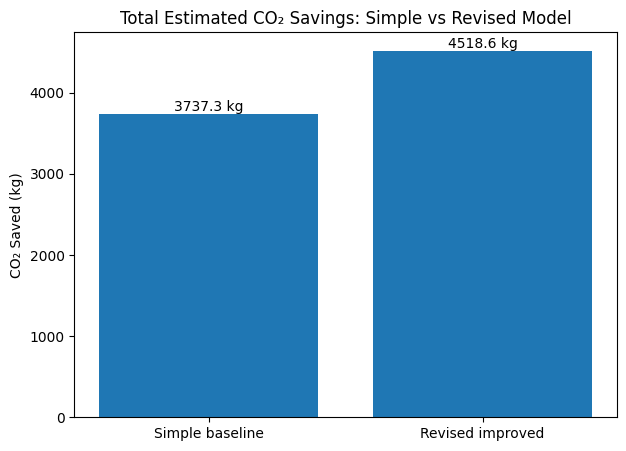

In [22]:
# ----------------------------------------------------
# Step 7C — Bar chart comparison of total CO2 savings
# ----------------------------------------------------

model_names = ["Simple baseline", "Revised improved"]
total_values = [simple_total, improved_total_v2]

plt.figure(figsize=(7, 5))
plt.bar(model_names, total_values)

plt.title("Total Estimated CO₂ Savings: Simple vs Revised Model")
plt.ylabel("CO₂ Saved (kg)")

for i, value in enumerate(total_values):
    plt.text(i, value, f"{value:.1f} kg", ha="center", va="bottom")

plt.show()

### Visual Comparison of Simple and Revised Models

The maps below compare the simple baseline CO₂ savings model with the revised improved model.

The same color scale is used for both maps to make the comparison fair. This allows us to see whether the revised road-attribute-based model changes the spatial pattern and intensity of estimated CO₂ savings.

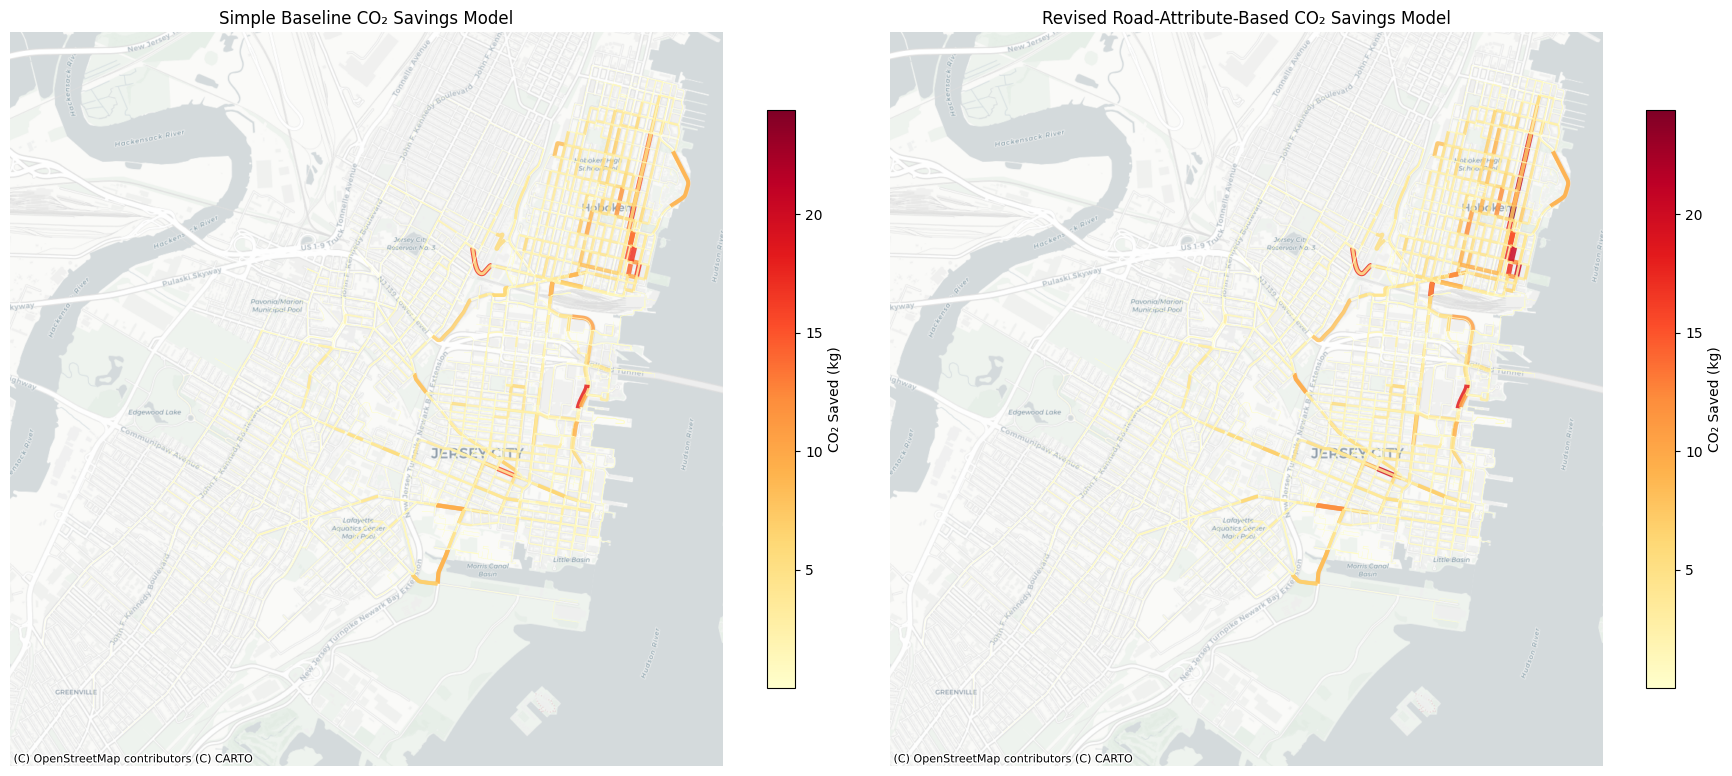

In [23]:
# ----------------------------------------------------
# Step 7D — Side-by-side map comparison
# ----------------------------------------------------

flow_web = flow_gdf.to_crs(epsg=3857)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Same color scale for both maps
vmin = min(
    flow_web["co2_saved_kg_simple"].min(),
    flow_web["co2_saved_kg_improved_v2"].min()
)

vmax = max(
    flow_web["co2_saved_kg_simple"].max(),
    flow_web["co2_saved_kg_improved_v2"].max()
)

# -------------------------------
# Simple baseline model
# -------------------------------
flow_web.plot(
    ax=axes[0],
    column="co2_saved_kg_simple",
    cmap="YlOrRd",
    linewidth=np.log1p(flow_web["co2_saved_kg_simple"]) * 1.2 + 0.2,
    alpha=0.85,
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        "label": "CO₂ Saved (kg)",
        "shrink": 0.75
    }
)

ctx.add_basemap(axes[0], source=ctx.providers.CartoDB.Positron)
axes[0].set_title("Simple Baseline CO₂ Savings Model")
axes[0].axis("off")


# -------------------------------
# Revised improved model
# -------------------------------
flow_web.plot(
    ax=axes[1],
    column="co2_saved_kg_improved_v2",
    cmap="YlOrRd",
    linewidth=np.log1p(flow_web["co2_saved_kg_improved_v2"]) * 1.2 + 0.2,
    alpha=0.85,
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        "label": "CO₂ Saved (kg)",
        "shrink": 0.75
    }
)

ctx.add_basemap(axes[1], source=ctx.providers.CartoDB.Positron)
axes[1].set_title("Revised Road-Attribute-Based CO₂ Savings Model")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Interpretation — Simple vs Revised Model Maps

The side-by-side maps compare the original simple baseline emissions model with the revised road-attribute-based model.

The broad spatial pattern remains similar in both maps because both models are based on the same traffic flow dataset and road segment lengths. Therefore, high-flow corridors continue to dominate the estimated CO₂ savings in both cases.

However, the revised model changes the intensity of the estimates by applying road-specific emission factors. These factors account for road type, speed context, lane count, and segment-length-related interruption effects. As a result, some segments become more prominent in the revised model, while others remain similar or receive lower relative emphasis.

The total estimated CO₂ savings increase from 3737.27 kg in the simple baseline model to 4518.61 kg in the revised model. This corresponds to an increase of 781.35 kg, or approximately 20.91%.

This comparison shows that the revised model still preserves the underlying mobility pattern, but it adds an additional layer of road-segment heterogeneity. Therefore, the revised model is more differentiated than the original constant-factor model.

### Difference Map — Revised Model Minus Simple Baseline Model

To better understand where the revised model changes the emissions estimates, a difference map is created.

The difference is calculated as:

$$
\Delta CO₂ = CO₂_{revised} - CO₂_{simple}
$$

Positive values indicate segments where the revised model estimates higher CO₂ savings than the simple baseline model. Negative values indicate segments where the revised model estimates lower CO₂ savings.

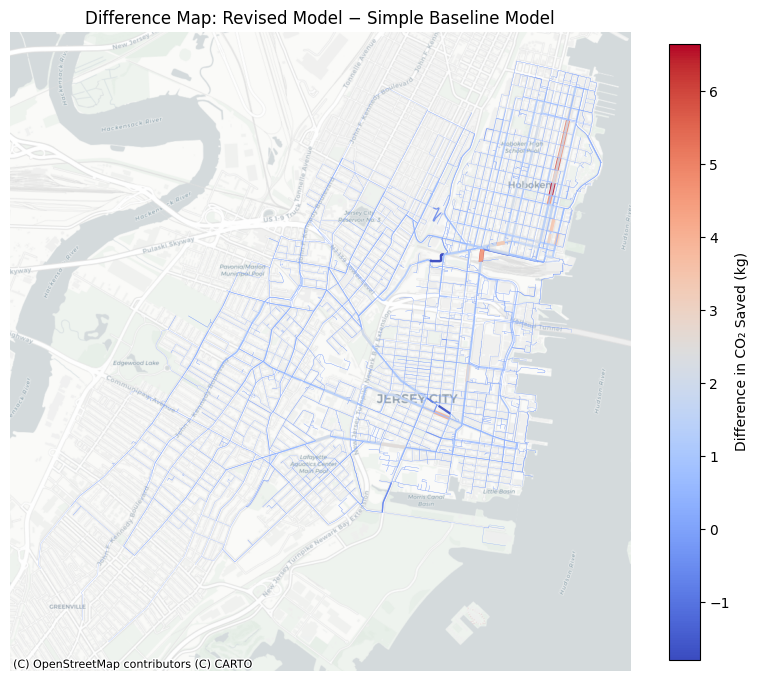

In [24]:
# ----------------------------------------------------
# Step 7E — Difference map: revised improved model minus simple model
# ----------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 10))

flow_web.plot(
    ax=ax,
    column="co2_difference_kg_v2",
    cmap="coolwarm",
    linewidth=np.log1p(abs(flow_web["co2_difference_kg_v2"])) * 1.5 + 0.2,
    alpha=0.85,
    legend=True,
    legend_kwds={
        "label": "Difference in CO₂ Saved (kg)",
        "shrink": 0.8
    }
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.set_title("Difference Map: Revised Model − Simple Baseline Model")
ax.axis("off")

plt.show()

### Interpretation — Difference Map

The difference map shows where the revised model estimates higher or lower CO₂ savings compared with the simple baseline model.

Positive values indicate segments where the revised road-attribute-based model estimates higher CO₂ savings. These increases occur where the adjusted emission factor is higher than the original constant emission factor. This is usually linked to road characteristics such as more motor-vehicle-oriented road types, higher lane counts, lower-speed stop-start conditions, or short segments with higher interruption effects.

The strongest differences appear on selected corridors rather than uniformly across the whole network. This suggests that the revised model is not simply multiplying the entire result by one constant. Instead, it changes the estimates differently depending on local road characteristics.

At the same time, many segments show relatively small differences. This is expected because traffic flow and segment length remain the main structural inputs in both models.

It shows that the revised emissions estimate is still grounded in observed bike flow patterns, but it now also reflects road-segment characteristics.

## Step 8 — Save the Revised Emissions Dataset

The revised emissions model has now produced road-segment-level CO₂ savings estimates using both the simple baseline model and the improved road-attribute-based model.

To make the results reusable for later analysis, visualization, and Task 5 scenario modelling, the final emissions dataset is saved in two formats:

- **GeoPackage (`.gpkg`)**: preserves geometry and is suitable for GIS-based analysis.
- **CSV (`.csv`)**: stores the attribute table without geometry and is useful for statistical analysis or reporting.

The final dataset includes:

- road segment identifiers (`u`, `v`),
- traffic flow (`total_flow`),
- segment length,
- road type,
- speed and lane information,
- source tracking for imputed/assumed values,
- simple baseline CO₂ savings,
- revised improved CO₂ savings,
- and the difference between the two models.

This dataset is the main emissions modelling output of Task 4.

In [25]:
# ----------------------------------------------------
# Step 8 — Save revised emissions dataset
# ----------------------------------------------------

# Select final columns for export
final_emissions_gdf = flow_gdf[
    [
        "u",
        "v",
        "total_flow",
        "length_m",
        "length_km",
        "highway_clean",
        "maxspeed_mph",
        "final_speed_mph",
        "speed_source",
        "lanes_clean",
        "final_lanes",
        "lane_source",
        "adjusted_EF_g_per_km_v2",
        "co2_saved_kg_simple",
        "co2_saved_kg_improved_v2",
        "co2_difference_kg_v2",
        "co2_difference_percent_v2",
        "geometry"
    ]
].copy()

# Save as GeoPackage
final_emissions_gdf.to_file(
    "emissions_revised_road_segments.gpkg",
    driver="GPKG"
)

# Save attribute table as CSV without geometry
final_emissions_gdf.drop(columns="geometry").to_csv(
    "emissions_revised_road_segments.csv",
    index=False
)

print("Revised emissions datasets saved successfully.")
print("GeoPackage: emissions_revised_road_segments.gpkg")
print("CSV: emissions_revised_road_segments.csv")

print("\nFinal emissions dataset shape:")
print(final_emissions_gdf.shape)

final_emissions_gdf.head()

Revised emissions datasets saved successfully.
GeoPackage: emissions_revised_road_segments.gpkg
CSV: emissions_revised_road_segments.csv

Final emissions dataset shape:
(5631, 18)


,u,v,total_flow,length_m,length_km,highway_clean,maxspeed_mph,final_speed_mph,speed_source,lanes_clean,final_lanes,lane_source,adjusted_EF_g_per_km_v2,co2_saved_kg_simple,co2_saved_kg_improved_v2,co2_difference_kg_v2,co2_difference_percent_v2,geometry
0,5451987123,297110085,238,46.263959,0.046264,tertiary,20.0,20.0,observed_from_OSM,NaN,2.0,imputed_from_highway_and_speed,288.737460,2.432841,3.179237,0.746396,30.680,"LINESTRING (-74.03022 40.73586, -74.03032 40.7..."
1,297110085,297110097,206,46.277329,0.046277,tertiary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM,288.737460,2.106345,2.752572,0.646227,30.680,"LINESTRING (-74.03037 40.73546, -74.03038 40.7..."
2,297110097,7217917595,206,20.824373,0.020824,tertiary,20.0,20.0,observed_from_OSM,2.0,2.0,observed_from_OSM,307.451925,0.947836,1.318914,0.371078,39.150,"LINESTRING (-74.0309 40.73551, -74.03115 40.73..."
3,7217917595,103866250,207,26.904055,0.026904,tertiary,20.0,20.0,observed_from_OSM,3.0,3.0,observed_from_OSM,317.611206,1.230501,1.768821,0.538320,43.748,"LINESTRING (-74.03115 40.73555, -74.03128 40.7..."
4,103866250,4988900669,78,34.830991,0.034831,secondary,20.0,20.0,observed_from_OSM,3.0,3.0,observed_from_OSM,360.921825,0.600281,0.980559,0.380278,63.350,"LINESTRING (-74.03146 40.73561, -74.03143 40.7..."


### Interpretation

The revised emissions dataset was saved successfully.

The final dataset contains 5,631 road segments, matching the number of flow segments from Task 3. This confirms that no road segments were lost during the emissions modelling process.

The saved GeoPackage preserves the spatial geometry of each road segment and can be used for mapping or GIS analysis. The CSV version provides a non-spatial attribute table for summary statistics, reporting, or further comparison.

This dataset satisfies the first expected output of Task 4: an emissions dataset with estimated CO₂ savings per road segment.

It also provides a useful input for Task 5, where scenario modelling can compare baseline and intervention cases using the same revised emissions framework.

## Final Discussion

### Summary of the Revised Emissions Model

This revised emissions modelling task estimated the potential CO₂ savings from bicycle trips by asking a counterfactual question:

> If these bicycle trips had instead been made by motor vehicles, how much CO₂ would likely have been produced?

The original simple model estimated CO₂ savings using:

$$
CO₂_{simple} = flow \times length \times EF_{weighted}
$$

where the same weighted average emission factor was applied to all road segments.

In the revised model, the emission factor was adjusted for each road segment using road characteristics extracted from OpenStreetMap:

$$
CO₂_{revised} = flow \times length \times EF_{adjusted}
$$

where:

$$
EF_{adjusted} = EF_{base} \times F_{roadtype} \times F_{speed} \times F_{lanes} \times F_{interruption}
$$

This means the revised model accounts for:

- road type,
- speed context,
- lane count,
- and segment-length-related interruption effects.

This improvement directly addresses the limitation of the earlier model, where the emissions map closely resembled the traffic flow map because the emission factor was mostly constant.

### Key Results

The simple baseline model estimated total CO₂ savings of approximately 3737.27 kg.

The revised road-attribute-based model estimated total CO₂ savings of approximately 4518.61 kg.

This represents an increase of approximately 781.35 kg, or 20.91%, compared with the simple baseline model.

At the segment level, the revised model also produced a wider distribution of emissions savings:

- the mean segment-level CO₂ savings increased from 0.664 kg to 0.802 kg,
- the median increased from 0.097 kg to 0.119 kg,
- and the maximum segment-level value increased from 17.96 kg to 24.40 kg.

These results show that the revised model introduces meaningful variation across road segments. The emissions estimates are still strongly influenced by traffic flow and segment length, but they are no longer determined by these two variables alone.

### Why the Revised Model Is an Improvement

The revised model improves the original emissions model in three main ways.

First, it introduces road-type variation. Different road classes are treated differently because motor-vehicle conditions are not expected to be identical on trunk roads, primary roads, residential streets, service roads, cycleways, and pedestrian links.

Second, it incorporates speed and lane context. These variables are not perfect substitutes for measured vehicle speeds or traffic composition, but they help represent differences in the road environment.

Third, it includes an interruption factor based on segment length. This responds to the idea that very short urban segments may involve more stopping, turning, and acceleration, while longer segments may allow smoother movement. Therefore, emissions are not assumed to increase purely proportionally with length.

Overall, the revised model remains simple and interpretable, but it is more realistic than a constant-factor approach because it allows road-segment characteristics to influence the final estimates.

### Assumptions

Several assumptions were made in this revised emissions model.

1. Bike trips are treated as replaced motorized trips  
   The model assumes that each observed bike trip could have otherwise been made by a motor vehicle. Therefore, the calculated values represent estimated emissions saved, not direct emissions produced.

2. A mixed-fleet base emission factor is used  
   The base emission factor represents a simplified mixed vehicle fleet. It does not describe the exact vehicle fleet composition in Jersey City or Hoboken.

3. Road attributes are used as proxies 
   Road type, speed, lanes, and segment length are used as proxies for motor-vehicle operating conditions. They do not directly measure actual vehicle behavior.

4. Missing road attributes are filled transparently  
   Missing speed and lane values were filled using a hierarchy: observed OSM values first, then imputation from similar edges, and finally fallback road-type assumptions.

5. Adjustment factors are simplified  
   The road type, speed, lane, and interruption factors are modelling assumptions. They are designed to introduce realistic variation, not to represent exact measured emission rates.

### Limitations

The revised model is more detailed than the simple baseline model, but it still has several limitations.

First, the model does not use measured traffic speeds. Speed values are either taken from OpenStreetMap, imputed from similar edges, or assumed based on road type. Actual vehicle speed can vary by time of day, congestion, signal timing, and driver behavior.

Second, the model does not include real vehicle fleet composition. In reality, emissions depend on the share of petrol cars, diesel cars, electric vehicles, vans, trucks, vehicle age, engine technology, and occupancy.

Third, the model does not explicitly simulate acceleration, braking, congestion, cold starts, or stop-and-go traffic. These are important determinants of real-world emissions.

Fourth, the model assumes that each bike trip replaces a motorized trip. In reality, some bicycle trips may replace walking, public transport, or trips that would not have occurred.

Fifth, the adjustment factors are simplified and should not be interpreted as measured emission coefficients. They are used to create a more realistic scenario-based estimate than the constant-factor model.

Therefore, the results should be interpreted as approximate estimates of potential CO₂ savings, not as a precise emissions inventory.

### Policy and Planning Insights

The results suggest that bicycle mobility can provide meaningful environmental benefits, especially along high-demand corridors.

The revised model shows that the largest estimated CO₂ savings occur where high bicycle flows overlap with road characteristics associated with higher motor-vehicle emission potential. This means that some cycling corridors may be especially important from an environmental perspective.

From a planning point of view, this supports targeted investment in high-impact corridors. Improving bicycle infrastructure on these routes may help maintain or increase cycling demand and therefore increase potential emissions savings.

Examples of possible interventions include:

- protected bicycle lanes on high-demand corridors,
- safer junction treatments on short and interruption-prone segments,
- improved connectivity between major cycling corridors,
- and prioritizing cycling infrastructure in areas where bicycle trips replace potentially higher-emission motorized trips.

The analysis also shows the value of combining mobility modelling with environmental modelling. Traffic flow alone shows where people move, while emissions modelling helps estimate the environmental importance of those movements.